# Eksplorujemy modele `text-to-image`: `openai/dall-e-3` oraz  `openai/dall-e-2`

## Czym jest model `dall-e-3`?

* `dall-e-3` to model `text-to-image` stworzony przez OpenAI. 
* Potrafi generować obrazy na podstawie opisu tekstowego. 
* Generuje obrazy o rozdzielczościach `1024×1024`, `1024×1792` oraz `1792×1024`. 
* Potrafi działać w dwóch trybach jakości (quality) `Standard` oraz `HD`.
* [Dokumentacja](https://platform.openai.com/docs/guides/images?context=node)
* Wejście: tekst
* Wyjście: obraz

## Czym jest model `dall-e-2`?

* `dall-e-2` to model `text-to-image` stworzony przez OpenAI.
* Potrafi generować obrazy na podstawie opisu tekstowego.
* Generuje obrazy o rozdzielczościach `256×256`, `512×512` oraz `1024×1024`.
* Jest znacznie tańszy w użyciu niż `dall-e-3`.
* Wejście: tekst
* Wyjście: obraz

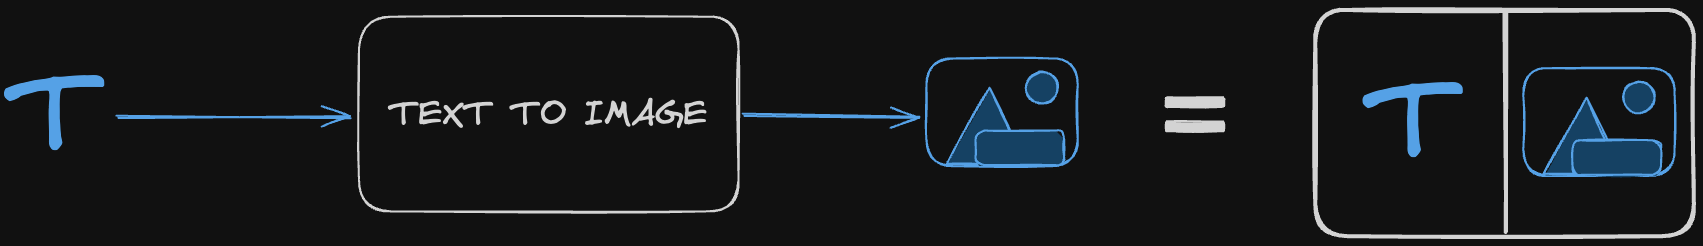

## Koszty

* Modele do generowania obrazu są bardzo kosztowne. 
* Wymagają dużo mocy obliczeniowej oraz dużo czasu.
* Naliczanie jest per obraz, a nie per zapytanie.
* Najtańszy opcja to `Standard` z `1024×1024` obrazem, który kosztuje `$0.040` (około `0.16 PLN`) za obraz.

Przykładowe estymacje:
* `Standard` z `1024×1024` obrazem: `$0.040` (około `0.16 PLN`) za obraz
* Jeżeli chcemy wygenerować 100 obrazów, to koszt wyniesie `$4.00` (około `16 PLN`)
* Jeżeli Twoja aplikacja umożliwia generowanie opowiadań do których można dołączyć obraz np. 10 obrazów i umożliwiasz generowanie do 10 opowiadań na miesiąc, to koszt wyniesie `10 * 10 * 0.16 PLN = 16 PLN`

UWAGA! Jeżeli te koszta są dla Ciebie zbyt wysokie, to polecamy skorzystanie z tańszego modelu `dall-e-2` w rozdzielczości `256×256` za `$0.016` (około `0.06 PLN`) za obraz.

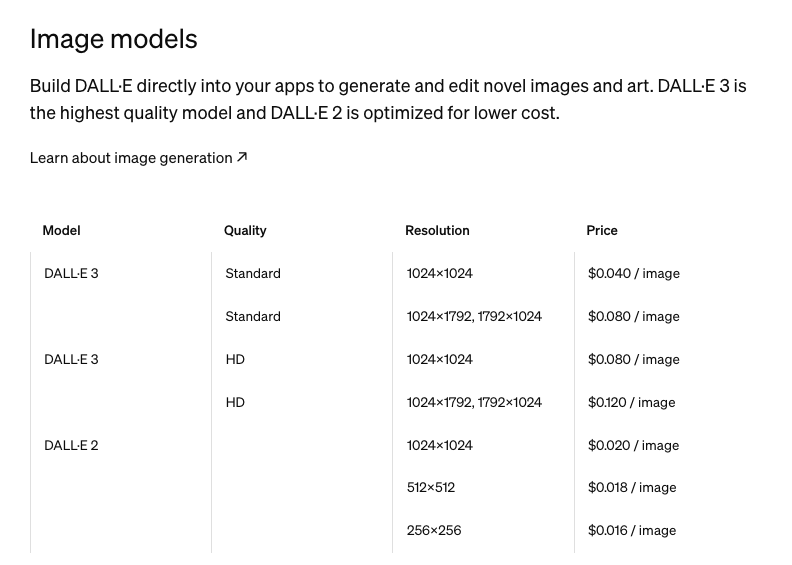

## Instalujemy wymagane biblioteki (conda wymagana)

- otwórz terminal
- uruchom `conda activate od_zera_do_ai`
- uruchom `conda install -y openai==1.47.0 python-dotenv requests`

In [ ]:
from dotenv import dotenv_values
from openai import OpenAI
from IPython.display import Markdown, Image
import requests

In [ ]:
env = dotenv_values(".env")

openai_client = OpenAI(api_key=env["OPENAI_API_KEY"])

## Jak używać modelu `dall-e-3`?

In [ ]:
response = openai_client.images.generate(
    model="dall-e-3",
    prompt="style pasteli, biały kot syjamski siedzący na parapecie na którym stoją doniczki z kwiatami, biała rama okna",
    size="1024x1024",
    quality="standard",
    n=1,
)

In [ ]:
# Dall-E 3 konweruje nasz tekst na bardziej szczegółowy opis
Markdown(response.data[0].revised_prompt)

In [ ]:
# obrazek możemy zapisać na dysku
with open("dall_e_3__kot_siedzi_na_parapecie.png", "wb") as f:
    f.write(requests.get(response.data[0].url).content)

In [ ]:
Image("dall_e_3__kot_siedzi_na_parapecie.png")

## Zamykamy model w funkcji

In [ ]:
def generate_image(
    text,
    output_path,
):
    response = openai_client.images.generate(
        model="dall-e-3",
        prompt=text,
        size="1024x1024",
        quality="standard",
        n=1,
    )
    with open(output_path, "wb") as f:
        f.write(requests.get(response.data[0].url).content)

    return Image(output_path)


In [ ]:
generate_image(
    text="biała kartka, czarne linie, styl kolorowanki dla dzieci, w centrum kot siedzi na parapecie, na parapecie stoją doniczki z kwiatami, za oknem widać drzewa",
    output_path="dall_e_3__kolorowanka_.png",
)

## Jak używać modelu `dall-e-2`?

In [ ]:
def generate_cheap_image(
    text,
    output_path,
):
    response = openai_client.images.generate(
        model="dall-e-2",
        prompt=text,
        size="1024x1024",
        n=1,
    )
    with open(output_path, "wb") as f:
        f.write(requests.get(response.data[0].url).content)

    return Image(output_path)


In [ ]:
generate_cheap_image(
    text="biała kartka, czarne linie, styl kolorowanki dla dzieci, w centrum kot siedzi na parapecie, na parapecie stoją doniczki z kwiatami, za oknem widać drzewa",
    output_path="dall_e_2__kolorowanka.png",
)

## Pomysły `gpt-4o` na użycie modelu

### 1. Generowanie Kolorowanek dla Dzieci
Model AI może tworzyć proste ilustracje na podstawie opisów, które następnie można przekształcić w kolorowanki dla dzieci. Na przykład, wpisanie "mały, uśmiechnięty lew pod drzewem" wygeneruje rysunek do pokolorowania.

### 2. Ilustracje do eBooków i Książek Dla Dzieci
Autorzy mogą używać modelu AI do tworzenia ilustracji na podstawie opisów scen z książek, co szczególnie przydaje się w literaturze dziecięcej. Każdy rozdział lub kluczowy moment w historii może być zilustrowany unikalnym obrazem.

### 3. Projektowanie Wnętrz na Podstawie Opisów
Model AI może generować wizualizacje wnętrz na podstawie opisów, takich jak "przytulny salon z kominkiem i drewnianymi meblami". To narzędzie może być wykorzystywane przez architektów wnętrz i osoby urządzające mieszkania.

### 4. Tworzenie Reklam Produktów
Firmy mogą używać AI do generowania obrazów reklamowych na podstawie opisów produktów. Na przykład, opis "butelka wody na tle górskiego krajobrazu" może wygenerować wizualizację, która idealnie wpasuje się w kampanię reklamową.

### 5. Generowanie Grafik Edukacyjnych
Nauczyciele i twórcy materiałów edukacyjnych mogą używać AI do tworzenia ilustracji wyjaśniających trudne koncepty na podstawie prostych opisów. Na przykład, "schemat cyklu wodnego" może zostać przekształcony w ilustrację przedstawiającą ten proces.

### 6. Tworzenie Personalizowanych Kart Okolicznościowych
Użytkownicy mogą wpisywać opisy, a model AI wygeneruje unikalne obrazy, które mogą być wykorzystane do tworzenia personalizowanych kart okolicznościowych na urodziny, święta, rocznice itp.

### 7. Generowanie Modowych Projektów na Podstawie Opisów
Projektanci mody mogą używać AI do generowania wstępnych projektów ubrań na podstawie opisów, takich jak "elegancka sukienka wieczorowa w kolorze bordo z długimi rękawami". To może przyspieszyć proces tworzenia kolekcji.

### 8. Tworzenie Ilustracji do Gier Planszowych
Twórcy gier planszowych mogą używać AI do generowania unikalnych grafik na podstawie opisów postaci, miejsc czy przedmiotów, które pojawiają się w grze. Na przykład, "średniowieczny rycerz z mieczem" może być przekształcony w obraz do gry.

### 9. Personalizowane Tapety na Pulpit i Ekrany Blokady
Użytkownicy mogą wpisywać opisy swoich wymarzonych tapet, a AI wygeneruje dla nich unikalne obrazy, które mogą ustawić jako tło pulpitu lub ekranu blokady.

### 10. Generowanie Okładek Albumów Muzycznych
Muzycy i wytwórnie mogą używać AI do tworzenia okładek albumów na podstawie opisów, które oddają nastrój lub tematykę muzyki. Na przykład, "minimalistyczna, czarno-biała okładka z abstrakcyjnymi liniami" może zostać wygenerowana jako okładka albumu.